<a href="https://colab.research.google.com/github/vencov/FAV_upsidedown/blob/main/BaysianActiveLearning/EX_audiogram_active_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fast audiogram estimation with Bayesian active learning
### A step-by-step walk-through of the Yes/No procedure

Based on: Schlittenlacher, Turner & Moore (2018), *Audiogram estimation using Bayesian active learning*, J. Acoust. Soc. Am. **144**, 421–430 (the Yes/No ML method, itself building on Song et al., 2015 and Houlsby et al., 2011).

**The measurement is a loop:**

1. Keep a probabilistic model of *P(tone heard)* as a function of frequency and level (a Gaussian-process classifier).
2. Use all answers so far to update the model.
3. Choose the next (frequency, level) as the one that is expected to teach us the most about the whole audiogram (maximum mutual information).
4. Play it, record *heard / not heard*, go to 2.

This notebook re-implements the idea from scratch with `numpy`/`scipy` only, and runs a **simulated listener** so that we know the true audiogram and can see how fast the estimate converges.

> This is a didactic re-implementation, not the authors' code. Hyperparameters that the paper gives are used as stated; the inference method and a few details are my own simplifications and are listed at the end.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.linalg import cholesky, solve_triangular

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(1)          # fixed seed -> reproducible run

# ---- Settings taken from the paper -------------------------------------
GAMMA   = 0.01    # lapse rate: likelihood is scaled to span 0.01 ... 0.99
SIGMA   = 3.0     # dB, SD of the Gaussian-CDF likelihood (psychometric slope)
ELL     = 0.5     # octaves, length scale of the squared-exponential kernel in frequency
L_MIN, L_MAX = 10.0, 77.0   # dB HL, allowed presentation levels

# ---- Settings that are my own choice (prior scales of the linear kernel)
SB, SA = 40.0, 1.0   # prior SD of the 'offset' b(f) and the 'slope' a(f), see section 2

## 0. Conventions

Frequency enters the model as **octaves relative to 1 kHz**, $o=\log_2(f/1000)$, so 125 Hz is $o=-3$ and 8 kHz is $o=+3$. A point in the "stimulus space" is $x=(o, L)$ with $L$ the level in dB HL. Candidate stimuli live on a grid with 0.1-octave spacing in frequency (as in the paper) and 1 dB spacing in level.

In [2]:
freqs_oct = np.arange(-3, 3.0001, 0.1)          # 125 Hz ... 8 kHz, 0.1 octave steps
levels    = np.arange(0, 78, 1.0)               # dB HL
nf, nl    = len(freqs_oct), len(levels)

# every (frequency, level) combination, ordered so that .reshape(nf, nl) works
Xg = np.column_stack([np.repeat(freqs_oct, nl), np.tile(levels, nf)])

FREQ_TICKS = [125, 250, 500, 1000, 2000, 4000, 8000]
def style_axes(ax, ylabel=True):
    ax.set_xticks(np.log2(np.array(FREQ_TICKS) / 1000))
    ax.set_xticklabels(["125", "250", "500", "1k", "2k", "4k", "8k"])
    ax.set_xlim(-3.1, 3.1); ax.set_ylim(0, 80)
    ax.set_xlabel("Frequency (Hz)")
    if ylabel: ax.set_ylabel("Level (dB HL)")

def show_map(ax, Z, title, cmap="viridis", vmin=None, vmax=None, cbar_label=None):
    # Z has shape (nf, nl)
    im = ax.imshow(Z.T, origin="lower", aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax,
                   extent=[freqs_oct[0] - 0.05, freqs_oct[-1] + 0.05, -0.5, 77.5])
    style_axes(ax); ax.set_title(title, fontsize=10)
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    if cbar_label: cb.set_label(cbar_label)
    return im

## 1. The (simulated) listener

To judge the method we need someone whose true threshold we know. Our listener has a sloping high-frequency loss. On each trial they answer *"heard"* with a probability that follows a Gaussian-CDF psychometric function around their true threshold $T(f)$, plus a 1 % chance of a lapse (answering "wrong" regardless of level, e.g. pressing the wrong button).

$$P(\text{heard}\mid f, L) = 0.01 + 0.98\;\Phi\!\left(\frac{L - T(f)}{\sigma_\text{true}}\right)$$

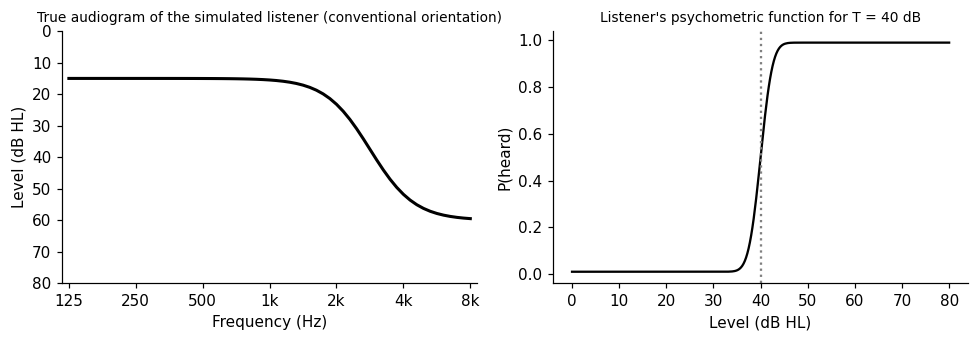

In [3]:
def true_T(f_hz):
    # true audiometric threshold (dB HL): mild low-frequency loss, sloping above ~2 kHz
    o = np.log2(np.asarray(f_hz) / 1000.0)
    return 15 + 45 / (1 + np.exp(-(o - 1.5) * 3))

SIGMA_TRUE = 2.0   # dB, slope of the listener's own psychometric function

def listen(o, L):
    # simulate one yes/no answer to a tone at octave o and level L
    p = 0.01 + 0.98 * norm.cdf((L - true_T(1000 * 2.0**o)) / SIGMA_TRUE)
    return int(rng.random() < p)

T_true = true_T(1000 * 2.0**freqs_oct)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(freqs_oct, T_true, "k", lw=2); style_axes(ax[0]); ax[0].invert_yaxis()
ax[0].set_ylim(80, 0); ax[0].set_title("True audiogram of the simulated listener (conventional orientation)", fontsize=9)
L = np.linspace(0, 80, 300)
ax[1].plot(L, 0.01 + 0.98 * norm.cdf((L - 40) / SIGMA_TRUE), "k")
ax[1].axvline(40, color="grey", ls=":"); ax[1].set_xlabel("Level (dB HL)"); ax[1].set_ylabel("P(heard)")
ax[1].set_title("Listener's psychometric function for T = 40 dB", fontsize=9)
plt.tight_layout(); plt.show()

## 2. The model: a Gaussian process over (frequency, level)

We do not fit a parametric audiogram. Instead we put a **prior over a latent function** $g(o, L)$ and let the data reshape it. Two ingredients define the model.

### 2a. Likelihood: from latent value to P(heard)

The latent value $g$ is turned into a probability by a Gaussian CDF whose range is squeezed to $[\gamma, 1-\gamma]$, which is what builds the **lapse rate** into the model:

$$P(y=1\mid g)=\gamma+(1-2\gamma)\,\Phi\!\left(\frac{g}{\sigma}\right),\qquad \gamma=0.01,\;\sigma=3\text{ dB}$$

So $g=0$ means "50 % heard" – **the audiogram is the contour $g(o,L)=0$.**

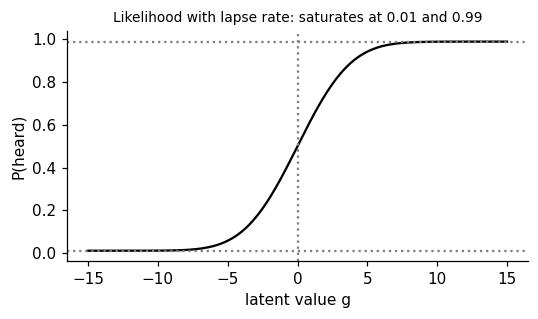

In [4]:
def p_heard(g):
    return GAMMA + (1 - 2 * GAMMA) * norm.cdf(g / SIGMA)

g = np.linspace(-15, 15, 300)
plt.figure(figsize=(5, 3))
plt.plot(g, p_heard(g), "k"); plt.axhline(GAMMA, color="grey", ls=":"); plt.axhline(1 - GAMMA, color="grey", ls=":")
plt.axvline(0, color="grey", ls=":"); plt.xlabel("latent value g"); plt.ylabel("P(heard)")
plt.title("Likelihood with lapse rate: saturates at 0.01 and 0.99", fontsize=9); plt.tight_layout(); plt.show()

### 2b. Prior: what do we know before measuring anything?

Two pieces of prior knowledge are encoded in the **kernel** $k(x,x')$, which sets the covariance of $g$ between any two stimuli:

* **Linear in level**: $g$ grows with level, so louder tones are more likely to be heard.
* **Squared-exponential in log-frequency** with length scale $\ell=0.5$ octave: thresholds at neighbouring frequencies are similar, and the similarity fades over about half an octave.

$$k\big((o,L),(o',L')\big)=\big(\sigma_b^2+\sigma_a^2\,L\,L'\big)\;\exp\!\left(-\frac{(o-o')^2}{2\ell^2}\right)$$

The product form means $g(o,L)=b(o)+a(o)\,L$, with $b(o)$ and $a(o)$ two independent smooth random functions of frequency. For each frequency, $g$ is a straight line in level; the threshold is where that line crosses zero. The prior mean is zero (no prior knowledge about where the threshold is). The scales $\sigma_b,\sigma_a$ were freely chosen (the paper does not state them in this text); they only need to be wide enough for $g$ to span the values $\pm$ a few $\sigma$ over the 0–77 dB range.

Below: three random "audiograms" drawn from the prior, shown as P(heard) maps. Note that they are smooth along frequency and monotonic along level, but otherwise know nothing about hearing.

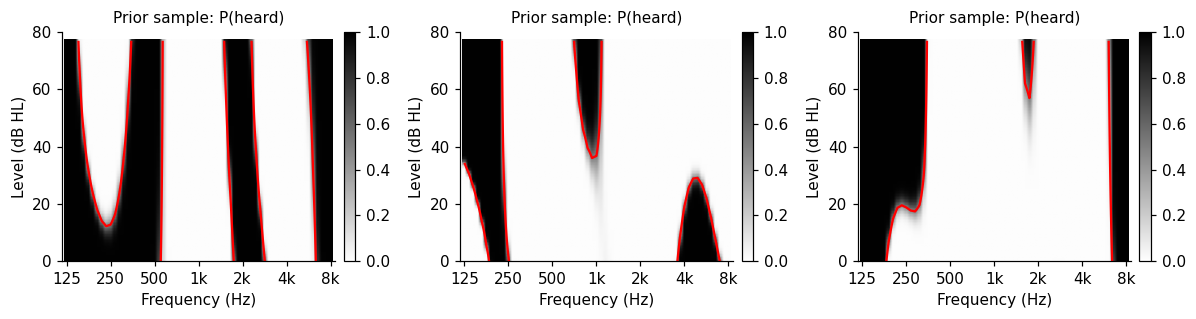

In [5]:
def kernel(X1, X2):
    d = X1[:, None, 0] - X2[None, :, 0]                               # octave difference
    lin = SB**2 + SA**2 * X1[:, None, 1] * X2[None, :, 1]            # linear in level
    return lin * np.exp(-0.5 * (d / ELL)**2)                          # x squared-exponential in frequency

def kdiag(X):
    return SB**2 + SA**2 * X[:, 1]**2                                 # k(x, x)

# sample from the prior using g = b(o) + a(o) * L  (equivalent to the kernel above)
Kf = np.exp(-0.5 * ((freqs_oct[:, None] - freqs_oct[None, :]) / ELL)**2) + 1e-8 * np.eye(nf)
Lf = cholesky(Kf, lower=True)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax in axes:
    b = SB * Lf @ rng.standard_normal(nf)
    a = SA * Lf @ rng.standard_normal(nf)
    G = b[:, None] + a[:, None] * levels[None, :]
    show_map(ax, p_heard(G), "Prior sample: P(heard)", cmap="gray_r", vmin=0, vmax=1)
    ax.contour(freqs_oct, levels, G.T, levels=[0], colors="r", linewidths=1.5)
plt.tight_layout(); plt.show()

## 3. Learning from answers: the posterior

After $n$ trials we have stimuli $X=\{x_i\}$ and answers $y_i\in\{0,1\}$. Bayes' rule gives the posterior over the latent values $g_i=g(x_i)$ at the tested points:

$$p(\mathbf g\mid D)\;\propto\;\underbrace{\mathcal N(\mathbf g;\,0,\,K)}_{\text{prior}}\;\prod_i\underbrace{P(y_i\mid g_i)}_{\text{likelihood}}$$

Because the likelihood is not Gaussian, this posterior has no closed form. Fast implementations approximate it analytically; **here we draw samples from it**, which is conceptually simple: each sample is *one plausible latent function that is consistent with all the answers so far*. We use **elliptical slice sampling**, which is designed for exactly this situation (Gaussian prior, arbitrary likelihood) and needs no tuning.

Once we have samples of $\mathbf g$ at the tested points, the latent function at *any* other stimulus $x_*$ follows from the ordinary GP conditioning formulas:

$$g(x_*)\mid\mathbf g\;\sim\;\mathcal N\!\Big(\mathbf k_*^\top K^{-1}\mathbf g,\;\;k(x_*,x_*)-\mathbf k_*^\top K^{-1}\mathbf k_*\Big)$$

so a set of posterior samples gives us a whole **ensemble of plausible psychometric surfaces**.

In [6]:
def posterior_samples(X, y, S=100, burn=80, thin=3):
    # Elliptical slice sampling of the latent values at the data points.
    # Returns what is needed to predict anywhere: Cholesky factor of K and
    # alpha_s = K^{-1} g_s for every posterior sample s.
    n = len(X)
    K = kernel(X, X) + 1e-6 * SB**2 * np.eye(n)       # small jitter for numerical stability
    Lc = cholesky(K, lower=True)                       # K = Lc Lc^T; g = Lc u with u ~ N(0, I)

    def loglik(g):
        z = (2 * y - 1) * g / SIGMA                    # sign flips for 'not heard' answers
        return np.log(GAMMA + (1 - 2 * GAMMA) * norm.cdf(z)).sum()

    # start the chain at the most probable function (MAP) so that no long burn-in is needed
    def neg_log_post(u):
        g = Lc @ u; z = (2 * y - 1) * g / SIGMA; c = 1 - 2 * GAMMA
        q = GAMMA + c * norm.cdf(z)
        dll = (2 * y - 1) * c * norm.pdf(z) / (SIGMA * q)
        return -np.log(q).sum() + 0.5 * u @ u, Lc.T @ (-dll) + u
    u = minimize(neg_log_post, np.zeros(n), jac=True, method="L-BFGS-B").x
    ll = loglik(Lc @ u)

    kept = []
    for it in range(burn + S * thin):
        nu = rng.standard_normal(n)                    # a fresh draw from the prior
        thresh = ll + np.log(rng.random())             # slice height
        th = rng.uniform(0, 2 * np.pi); lo, hi = th - 2 * np.pi, th
        while True:                                    # shrink the angle bracket until accepted
            u_new = u * np.cos(th) + nu * np.sin(th)   # point on the ellipse through u and nu
            ll_new = loglik(Lc @ u_new)
            if ll_new > thresh: break
            if th < 0: lo = th
            else:      hi = th
            th = rng.uniform(lo, hi)
        u, ll = u_new, ll_new
        if it >= burn and (it - burn) % thin == 0:
            kept.append(u.copy())
    U = np.array(kept).T                               # (n, S)
    return dict(X=X, Lc=Lc, A=solve_triangular(Lc.T, U, lower=False))   # A[:, s] = K^{-1} g_s

def predict(post, Xs):
    # conditional mean for every posterior sample, and the (sample-independent) conditional variance
    Ks = kernel(Xs, post["X"])                         # (n*, n)
    mu = Ks @ post["A"]                                # (n*, S)
    V  = solve_triangular(post["Lc"], Ks.T, lower=True)
    vc = np.maximum(kdiag(Xs) - (V**2).sum(0), 1e-9)   # (n*,)
    return mu, vc

def threshold_curve(post):
    # audiogram estimate: level where the posterior-mean latent function crosses zero (P = 0.5)
    mu, _ = predict(post, Xg)
    M = mu.mean(1).reshape(nf, nl)
    T = np.full(nf, np.nan)
    for i in range(nf):
        idx = np.where(M[i] >= 0)[0]
        if len(idx) == 0: continue                     # still above the highest tested level
        j = idx[0]
        T[i] = levels[0] if j == 0 else levels[j-1] + (0 - M[i, j-1]) / (M[i, j] - M[i, j-1])
    return T

## 4. Getting started: a few rule-based trials

A GP with zero data is useless for choosing stimuli, so the paper starts with simple rules that give the listener an easy start and bracket the threshold roughly in each octave: begin at 1 kHz and 60 dB HL; if the tone is heard go down in 20 dB steps, otherwise up in 10 dB steps, until one "heard" and one "not heard" answer exist (or a level limit is hit); then move to 2, 4, 8, 0.5, 0.25 and 0.125 kHz, starting each at 10 dB above the lowest heard level of the previous frequency.

*(Simplified version of the paper's rules.)*

21 initial trials


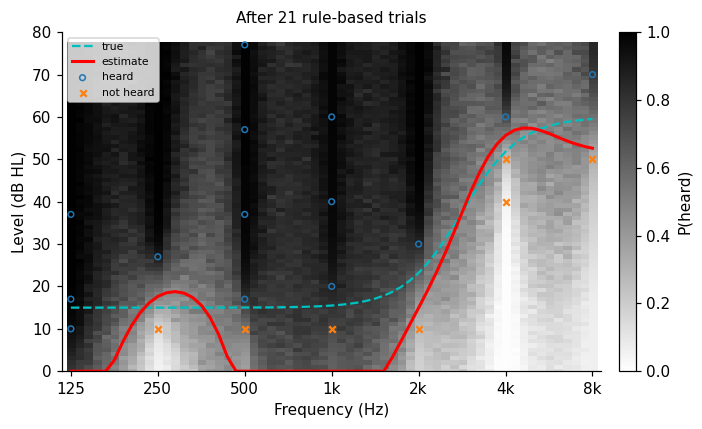

In [13]:
def initial_trials():
    X, y, prev = [], [], None
    for o in [0, 1, 2, 3, -1, -2, -3]:                       # 1k, 2k, 4k, 8k, 500, 250, 125 Hz
        L = 60.0 if prev is None else min(prev + 10, L_MAX)
        got_yes = got_no = False; lowest_yes = None
        for _ in range(8):
            r = listen(o, L); X.append([o, L]); y.append(r)
            if r: got_yes = True; lowest_yes = L if lowest_yes is None else min(lowest_yes, L)
            else: got_no = True
            if got_yes and got_no: break
            if r:                                              # heard -> go down 20 dB
                if L <= L_MIN: break
                L = max(L - 20, L_MIN)
            else:                                              # not heard -> go up 10 dB
                if L >= L_MAX: break
                L = min(L + 10, L_MAX)
        prev = lowest_yes if lowest_yes is not None else L_MAX
    return np.array(X), np.array(y)

X0, y0 = initial_trials()
print(f"{len(y0)} initial trials")

# visualise what the GP knows from just these trials
post0 = posterior_samples(X0, y0, S=200)
mu0, vc0 = predict(post0, Xg)
g_s = mu0 + np.sqrt(vc0)[:, None] * rng.standard_normal(mu0.shape)       # samples of g at every grid point
P0 = p_heard(g_s).mean(1).reshape(nf, nl)                                  # predictive P(heard)

def plot_state(ax, post, X, y, title):
    mu, vc = predict(post, Xg)
    gs = mu + np.sqrt(vc)[:, None] * rng.standard_normal(mu.shape)
    P = p_heard(gs).mean(1).reshape(nf, nl)
    show_map(ax, P, title, cmap="gray_r", vmin=0, vmax=1, cbar_label="P(heard)")
    ax.plot(freqs_oct, T_true, "c--", lw=1.5, label="true")
    T = threshold_curve(post); ax.plot(freqs_oct, T, "r", lw=2, label="estimate")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=14, facecolors="none", edgecolors="tab:blue", label="heard")
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=18, marker="x", color="tab:orange", label="not heard")

fig, ax = plt.subplots(figsize=(6.5, 4))
plot_state(ax, post0, X0, y0, f"After {len(y0)} rule-based trials"); ax.legend(fontsize=7, loc="upper left"); plt.tight_layout(); plt.show()

The grey map is the model's predicted probability that a tone is heard; the red line is the 50 % contour (the current audiogram estimate), the cyan dashed line is the truth (hidden from the algorithm). With about twenty answers the estimate is crude, and between the tested frequencies it is mostly the prior's smoothness doing the work.

Let us also look at the ensemble of *plausible psychometric functions* at one frequency. The more the curves disagree, the less we know there:

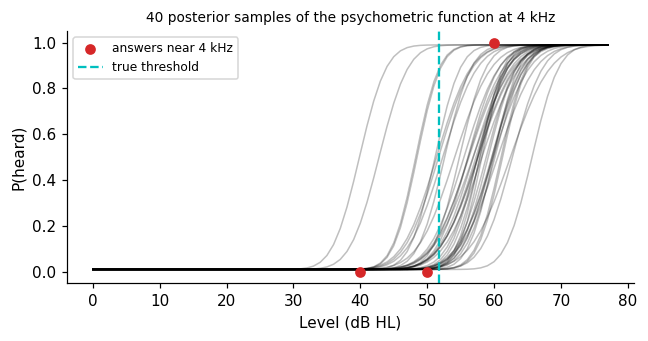

In [8]:
o_demo = 2.0                                   # 4 kHz
Xd = np.column_stack([np.full(nl, o_demo), levels])
mud, vcd = predict(post0, Xd)
plt.figure(figsize=(6, 3.2))
plt.plot(levels, p_heard(mud[:, :40]), color="k", alpha=0.25, lw=1)
sel = np.abs(X0[:, 0] - o_demo) < 0.3
plt.scatter(X0[sel, 1], y0[sel], c="tab:red", zorder=3, label="answers near 4 kHz")
plt.axvline(true_T(4000), color="c", ls="--", label="true threshold")
plt.xlabel("Level (dB HL)"); plt.ylabel("P(heard)"); plt.legend(fontsize=8)
plt.title("40 posterior samples of the psychometric function at 4 kHz", fontsize=9); plt.tight_layout(); plt.show()

## 5. The core idea: how is the next tone chosen?

We want the tone whose answer is expected to tell us the most about the **whole function $g$**. Information theory gives a precise criterion, the mutual information between the (unknown) answer $y_*$ at a candidate stimulus $x_*$ and the latent function $g$:

$$I(y_*;g\mid x_*,D)\;=\;\underbrace{H\big[y_*\mid x_*,D\big]}_{\text{(i) how unsure is the answer?}}\;-\;\underbrace{\mathbb E_{g\mid D}\Big[H\big[y_*\mid x_*,g\big]\Big]}_{\text{(ii) how unsure would it be if we knew }g}$$

with $H$ the binary entropy, $H(p)=-p\log_2 p-(1-p)\log_2(1-p)$. Houlsby et al. (2011) showed this can be computed from entropies of the *answer* only, with no need for the (very costly) entropy of the whole GP; this is what makes it fast enough for the ~2 s between trials.

**How to read the two terms with our samples.** For each posterior sample $s$ we have a psychometric value $p_s(x_*)$ at the candidate stimulus.

* (i) is the entropy of the **average** $\bar p=\tfrac1S\sum_s p_s$: it is large when the model is, on average, unsure whether the tone is heard (near the threshold).
* (ii) is the **average of the entropies** $\tfrac1S\sum_s H(p_s)$: it measures the answer noise that each individual sample already explains.
* The difference is large only when the samples **disagree** with each other, each being fairly confident. That is exactly where one more answer will discard many of the competing hypotheses.

This is why the criterion avoids two kinds of useless stimuli: tones that are clearly audible or clearly inaudible (everyone agrees, (i) is small) and places that are already measured precisely (samples agree, (i) ≈ (ii)).

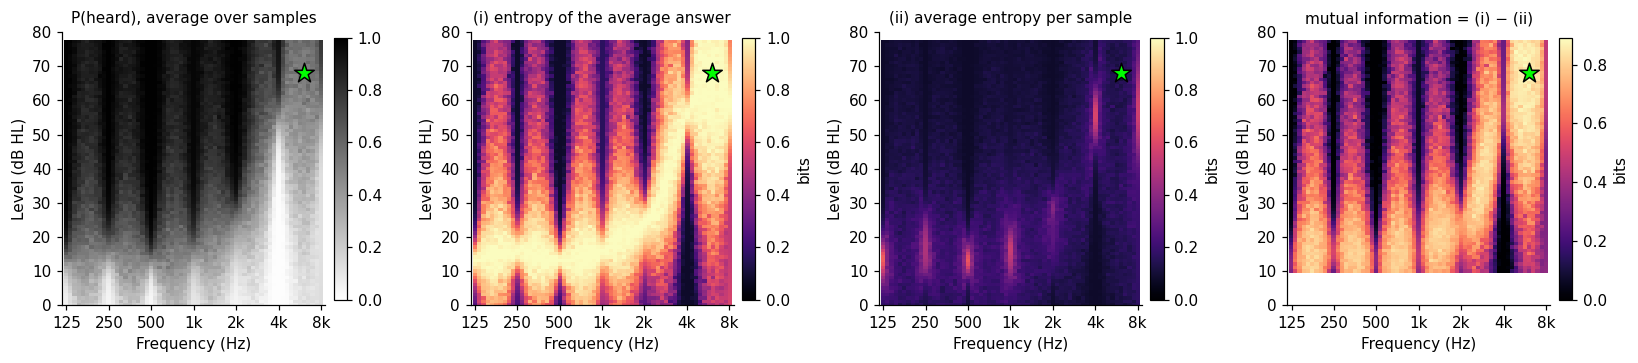

Next tone: 6063 Hz at 68 dB HL  (expected information 0.89 bit)


In [9]:
def entropy_bits(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def info_terms(mu, vc):
    # one draw of g(x*) for each posterior sample, then psychometric values p_s(x*)
    g = mu + np.sqrt(vc)[:, None] * rng.standard_normal(mu.shape)
    p = p_heard(g)                                         # (n*, S)
    pbar = p.mean(1)
    term1 = entropy_bits(pbar)                             # (i)  entropy of the average answer probability
    term2 = entropy_bits(p).mean(1)                        # (ii) average entropy under each sample
    return pbar, term1, term2, term1 - term2

def next_stimulus(post):
    mu, vc = predict(post, Xg)
    pbar, t1, t2, mi = info_terms(mu, vc)
    mi = np.where(Xg[:, 1] >= L_MIN, mi, -np.inf)          # respect the lowest allowed level
    k = np.argmax(mi)
    return Xg[k], mi, (pbar, t1, t2)

x_next, mi, (pbar, t1, t2) = next_stimulus(post0)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
show_map(axes[0], pbar.reshape(nf, nl), "P(heard), average over samples", cmap="gray_r", vmin=0, vmax=1)
show_map(axes[1], t1.reshape(nf, nl), "(i) entropy of the average answer", cmap="magma", vmin=0, vmax=1, cbar_label="bits")
show_map(axes[2], t2.reshape(nf, nl), "(ii) average entropy per sample", cmap="magma", vmin=0, vmax=1, cbar_label="bits")
mi_plot = np.where(np.isfinite(mi), mi, np.nan).reshape(nf, nl)
show_map(axes[3], mi_plot, "mutual information = (i) − (ii)", cmap="magma", vmin=0, cbar_label="bits")
for ax in axes: ax.scatter(*x_next, marker="*", s=180, color="lime", edgecolor="k", zorder=5)
plt.tight_layout(); plt.show()
print(f"Next tone: {1000*2**x_next[0]:.0f} Hz at {x_next[1]:.0f} dB HL  (expected information {mi.max():.2f} bit)")

The green star is the arg-max of the last panel: the stimulus the algorithm will play next. Panel (i) alone would simply pick the most uncertain answer anywhere; subtracting (ii) removes the part of the uncertainty that is just the listener's own psychometric noise, leaving the part that more data can reduce.

## 6. Closing the loop

One full measurement step = fit → choose → play → record. We repeat this until 100 signal trials have been collected (the paper additionally interleaves 20 silent catch trials to estimate the false-positive rate; we omit them here). We keep a few snapshots and track two diagnostics at every trial:

* the **RMS difference** between current estimate and the (here known) true audiogram, and
* the **information gain** of the chosen stimulus – available in a real test, where the truth is unknown.

*(The loop takes roughly half a minute.)*

In [10]:
def measure(n_total=100, snapshots=(30, 50, 100), S=100):
    X, y = X0.copy(), y0.copy()
    hist = dict(n=[], rmsd=[], mi=[], snap={})
    while len(y) < n_total:
        post = posterior_samples(X, y, S=S)                    # 1. update the model with all answers so far
        x, mi, _ = next_stimulus(post)                         # 2. most informative next tone
        T = threshold_curve(post)
        hist["n"].append(len(y)); hist["mi"].append(mi.max())
        hist["rmsd"].append(np.sqrt(np.nanmean((T - T_true)**2)))
        if len(y) in snapshots: hist["snap"][len(y)] = (post, X.copy(), y.copy())
        X = np.vstack([X, x]); y = np.append(y, listen(*x))    # 3. play it, 4. record the answer
    post = posterior_samples(X, y, S=200)
    hist["snap"][len(y)] = (post, X.copy(), y.copy())
    hist["final"] = (post, X, y)
    return hist

hist = measure()

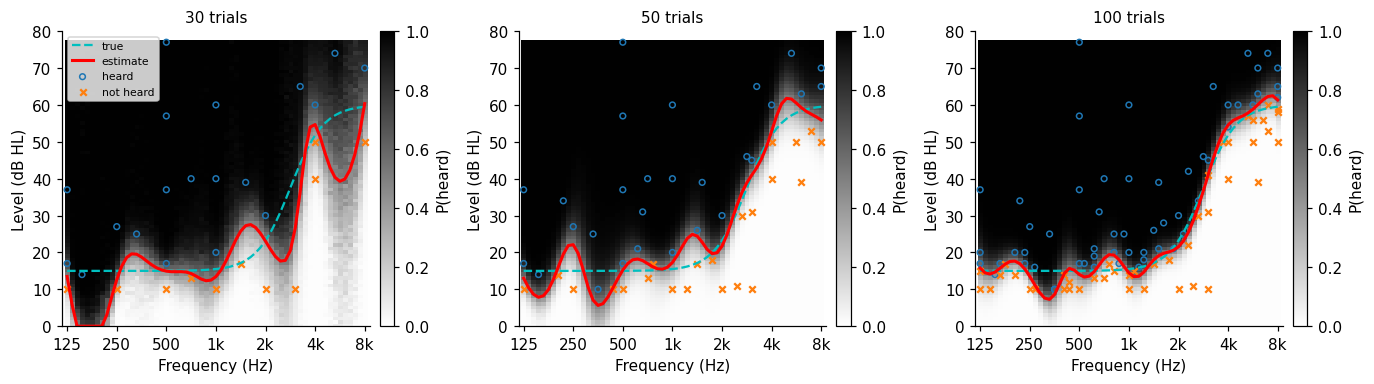

In [11]:
snaps = sorted(hist["snap"])
fig, axes = plt.subplots(1, len(snaps), figsize=(4.2 * len(snaps), 3.6))
for ax, n in zip(axes, snaps):
    post, X, y = hist["snap"][n]
    plot_state(ax, post, X, y, f"{n} trials")
axes[0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

Look at where the circles and crosses cluster: after the initial trials the algorithm concentrates stimuli **along the threshold curve** (that is where answers are uncertain), and it samples all frequencies (that is where the GP is still uncertain), while ignoring regions where the answer is already obvious.

## 7. How fast does it converge, and when to stop?

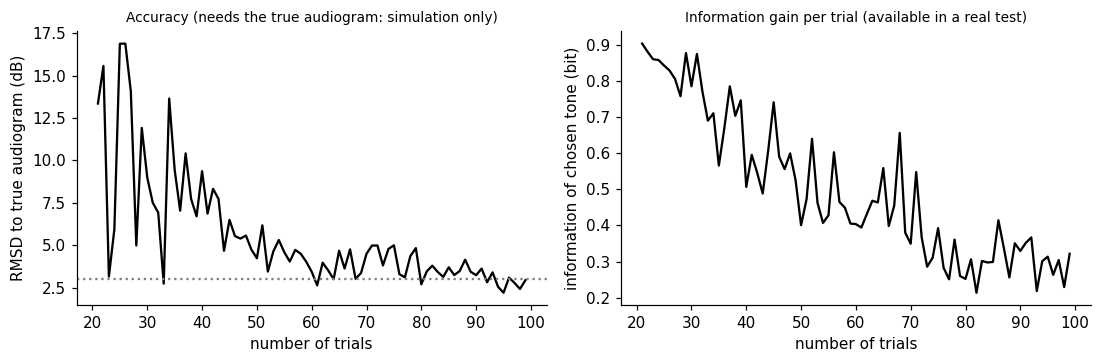

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(hist["n"], hist["rmsd"], "k"); ax[0].axhline(3, color="grey", ls=":")
ax[0].set_xlabel("number of trials"); ax[0].set_ylabel("RMSD to true audiogram (dB)")
ax[0].set_title("Accuracy (needs the true audiogram: simulation only)", fontsize=9)
ax[1].plot(hist["n"], hist["mi"], "k"); ax[1].set_xlabel("number of trials")
ax[1].set_ylabel("information of chosen tone (bit)")
ax[1].set_title("Information gain per trial (available in a real test)", fontsize=9)
plt.tight_layout(); plt.show()

The information of the best available tone drops as the model learns, and it tracks the true error. That is why the paper proposes it as a **stopping criterion**: stop when the expected gain per trial falls below a threshold that corresponds to the desired precision (the paper reports Spearman correlations of about 0.7–0.85 between information gain and RMSD).

Your numbers will differ from the paper's (they used 40 real ears; this is one simulated listener, my own prior scales, and sampling noise). In this run the error fluctuates strongly during the first 30–40 trials, because each new answer can still change the picture a lot, and then settles to roughly 3–5 dB after 60–100 trials. The paper reports faster convergence on real ears (RMSD below 3 dB after about 50 trials), so treat the numbers here as a qualitative demonstration, not a replication. Also note that the estimate can dip below the 10 dB floor of the test range where the true threshold is low; the paper likewise ignores estimates outside the tested limits.

## 8. Things to try

* **Lapse rate**: the simulated listener lapses on 1 % of trials (see `listen`). Compare a model with `GAMMA = 0.0`, `0.01` and `0.05`, and raise the listener's lapse rate. The paper argues that a lapse rate lets the method recover from a wrong answer given at an extreme level.
* **Length scale**: change `ELL` to 0.2 or 1.5 octaves and run the loop again. Make `true_T` contain a steep notch to see when a long length scale blurs it.
* **Slope**: the paper estimated an SD of about 1.5 dB for its Yes/No data (default used: 3 dB). Change `SIGMA` and `SIGMA_TRUE` together or separately.
* **Random seeds**: rerun `hist = measure()` several times and look at the spread of the convergence curves.
* **Drop the second term**: change `next_stimulus` to pick the grid point with the largest term (i) alone, or the one whose $\bar p$ is closest to 0.5, and compare the convergence curves with the full criterion.

## Differences from the paper

| | Paper (Yes/No ML) | This notebook |
|---|---|---|
| GP kernel / likelihood / lapse | linear (level) × SE (log f, ℓ = 0.5 oct); Gaussian CDF, σ = 3 dB, lapse 0.01 | same |
| Candidate grid | 0.1-octave frequency grid | same (plus 1 dB level grid) |
| Kernel amplitude scales | not given in the text | my own choice (`SB`, `SA`) |
| Posterior inference | tuned for ~2 s between trials | elliptical slice sampling, chosen for transparency |
| Mutual information | analytic form of Houlsby et al. (2011) | Monte-Carlo estimate from posterior samples |
| Initial trials | specific rule set | simplified version |
| Catch trials | 20 silent trials per ear | omitted |
| Listener | 40 real ears | one simulated listener |

The Counting ML method of the paper (six descending tones per trial, 7-ary answer) is not implemented here.

**References.** Schlittenlacher, J., Turner, R. E., & Moore, B. C. J. (2018). J. Acoust. Soc. Am. 144, 421–430. · Song, X. D. et al. (2015). Ear Hear. 36, e326–e335. · Houlsby, N. M. T. et al. (2011). arXiv:1112.5745. · Murray, I., Adams, R. P., & MacKay, D. J. C. (2010). Elliptical slice sampling. AISTATS.